# 🦜🕸️ LangGraph Prompt Chaining

Welcome! This notebook introduces **Prompt Chaining** — a design pattern where the output of one LLM call feeds into the next. We'll build a joke generation pipeline with a built-in quality gate.

| Concept | What it is | This example |
|---------|-----------|--------------|
| **State** | Shared data container | Holds `topic`, `joke`, `improved_joke`, `final_joke` |
| **Node** | An LLM call that updates State | `generate_joke`, `improve_joke`, `polish_joke` |
| **Edge** | Fixed connection between nodes | `improve_joke → polish_joke` |
| **Conditional Edge** | Routing function that picks the next node | `check_punchline` → `improve_joke` or `END` |

> **Goal:** by the end you'll understand how to chain LLM calls and add conditional branching in a LangGraph workflow.

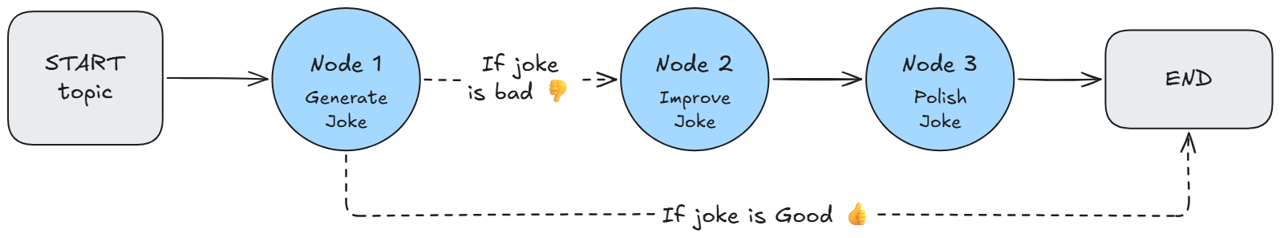

In [11]:
from IPython.display import Image, display
display(Image("images/2.png"))

<h3><center>  <div style="background-color:lightpink;border-radius:10px; padding: 10px;">Setup ⚙️</div></center></h3>

In [1]:
%pip install --quiet python-dotenv langchain langchain-core langchain-openai langgraph 


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Setting up the API keys
import sys
sys.path.insert(1, '../../')

import init_creds as creds

# Configure Azure OpenAI
AZURE_OPENAI_KEY = creds.get_api_key()
AZURE_OPENAI_ENDPOINT = creds.get_endpoint()
AZURE_OPENAI_API_VERSION = "2025-04-01-preview"

if not AZURE_OPENAI_KEY:
    raise ValueError("No AZURE_OPENAI_KEY set for Azure OpenAI API")
if not AZURE_OPENAI_ENDPOINT:
    raise ValueError("No AZURE_OPENAI_ENDPOINT set for Azure OpenAI API")

<h3><center>  <div style="background-color:skyblue;border-radius:10px; padding: 10px;">Prompt Chaining with LangGraph</div></center></h3>

In [3]:
from typing import Optional
from pydantic import BaseModel
from langchain_openai import AzureChatOpenAI
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

In [4]:
# LLM
llm = AzureChatOpenAI(
    model="gpt-4o-mini",
    azure_endpoint=AZURE_OPENAI_ENDPOINT,
    api_key=AZURE_OPENAI_KEY,
    api_version=AZURE_OPENAI_API_VERSION
)

#### What is Prompt Chaining? 🔗

**Prompt Chaining** breaks a complex task into a sequence of focused LLM calls, where each step refines the previous output. LangGraph makes the flow explicit through its graph structure.

A **conditional edge** acts as a quality gate — if the joke already has a punchline it exits early; otherwise it goes through two rounds of improvement.

#### 1. Define the State 🗂️

The `State` is a Pydantic `BaseModel` that holds all data flowing through the pipeline. Fields that may not always be populated (because the joke passes the quality gate early) are typed `Optional[str]` with a `None` default.

In [5]:
class State(BaseModel):
    topic: str
    joke: str = ""
    improved_joke: Optional[str] = None
    final_joke: Optional[str] = None

#### 2. Define the Nodes 🔧

Each **node** is a Python function that receives the current `State`, makes an LLM call, and returns a `dict` with the fields to update. With Pydantic state, fields are accessed as attributes (`state.topic`, `state.joke`).

```python
def my_node(state: State) -> dict:
    response = llm.invoke("...")
    return {"field": response.content}   # ← merged back into State
```

In [6]:
def generate_joke(state: State) -> dict:
    """First LLM call — generate an initial joke."""
    msg = llm.invoke(f"Write a short joke about {state.topic}")
    return {"joke": msg.content}


def improve_joke(state: State) -> dict:
    """Second LLM call — improve the joke with wordplay."""
    msg = llm.invoke(f"Make this joke funnier by adding wordplay: {state.joke}")
    return {"improved_joke": msg.content}


def polish_joke(state: State) -> dict:
    """Third LLM call — add a surprising twist."""
    msg = llm.invoke(f"Add a surprising twist to this joke: {state.improved_joke}")
    return {"final_joke": msg.content}

#### 3. Define the Edges and Build the Graph 🔗

This pipeline uses two types of edges:

| Edge type | API | When to use |
|-----------|-----|-------------|
| **Regular** | `workflow.add_edge(a, b)` | Always go to the same next node |
| **Conditional** | `workflow.add_conditional_edges(src, fn, map)` | Route dynamically based on State |

`check_punchline` is the **routing function** — it inspects the joke and returns a string key (`"Pass"` or `"Fail"`) that maps to the next node to execute.

In [7]:
# Conditional edge function
def check_punchline(state: State) -> str:
    """Routing function: returns 'Pass' if the joke has a punchline, else 'Fail'."""
    if "?" in state.joke or "!" in state.joke:
        return "Pass"
    return "Fail"


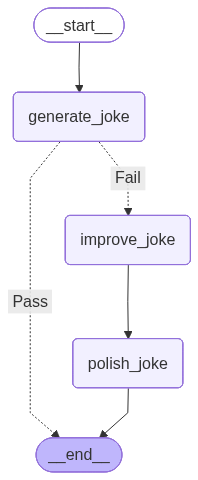

In [8]:
# Build workflow
workflow = StateGraph(State)

workflow.add_node("generate_joke", generate_joke)
workflow.add_node("improve_joke", improve_joke)
workflow.add_node("polish_joke", polish_joke)

workflow.add_edge(START, "generate_joke")
workflow.add_conditional_edges(
    "generate_joke", check_punchline, {"Fail": "improve_joke", "Pass": END}
)
workflow.add_edge("improve_joke", "polish_joke")
workflow.add_edge("polish_joke", END)

# Compile and visualise
graph = workflow.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

#### 4. Run the Graph ▶️

Call `graph.invoke(initial_state)` to execute the pipeline. LangGraph will:
1. Start with just `topic` in State
2. Run `generate_joke` — adds `joke`
3. Call `check_punchline` — routes to `improve_joke` (Fail) or exits (Pass)
4. Optionally run `improve_joke` → `polish_joke`
5. Return the **final, fully-updated State**

In [10]:
result = graph.invoke({"topic": "cats"})
result

{'topic': 'cats',
 'joke': 'Why did the cat sit on the computer?  \nBecause it wanted to keep an eye on the mouse!'}

#### Summary 📝

| Concept | Key API | Role |
|---------|---------|------|
| **State** | `BaseModel` | Shared data container for the whole run |
| **Node** | `workflow.add_node(name, fn)` | LLM call that reads State and returns partial updates |
| **Edge** | `workflow.add_edge(a, b)` | Fixed execution order between nodes |
| **Conditional Edge** | `workflow.add_conditional_edges(src, fn, map)` | Dynamic routing based on State |
| **Entry point** | `add_edge(START, name)` | Start of the workflow |
| **Termination** | `add_edge(name, END)` | Signals the graph is done |
| **Invoke** | `graph.invoke(state)` | Runs the full graph, returns final State |